# Assigment 1: Speech analysis
## TTT4185 Machine learning for Speech technology
This assignment assumes that the student has knowledge about short-time spectral estimation, linear prediction modeling and cepstral analysis. You should also know the concept of fundamental frequencies and formants.

Useful plotting commands from `matplotlib.pyplot`: `figure`, `plot`, `subplots`, `pcolormesh`



## Problem 1: Time-domain analysis

Included in the Blackboard post about this assignment is the audio file `stry.py`. Download the file then upload it to this Colab session.

The wav file is a recording of the latter half of the English word "tapestry". The phonetic transcription is /s/ /t/ /r/ /iy/.

Here's how you can load it using `scipy.io.wavefile.read` ([documentation here](https://docs.scipy.org/doc/scipy/reference/generated/scipy.io.wavfile.read.html))


In [17]:
# import relevant packages
import numpy as np
import scipy as sp
import scipy.io.wavfile

from matplotlib import pyplot as plt

In [18]:
# fetch and read the data
Fs, data = scipy.io.wavfile.read('stry.wav')

### Task 1

Plot the signal from the `stry.py` wavfile in the time domain.

What is characteristic about the sounds /s/, /t/, /r/ and /iy/? Can you easily tell apart /r/ and /iy/? Hint: /r/ starts around 0.22 seconds

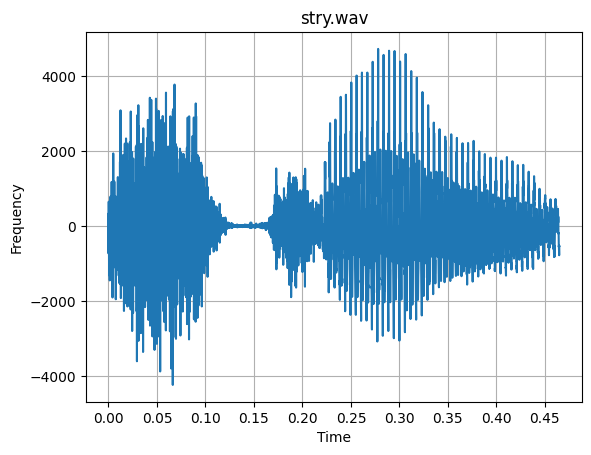

In [19]:
duration = len(data) / Fs
time = np.linspace(0, duration, num=len(data))


plt.plot(time, data)
plt.ylabel("Frequency")
plt.xlabel("Time")
plt.title("stry.wav")
plt.xticks([0,0.05,0.1,0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45])
plt.grid()

plt.show()

### Task 2

Take a 40 millisecond subset of the vowel /iy/ and plot it.


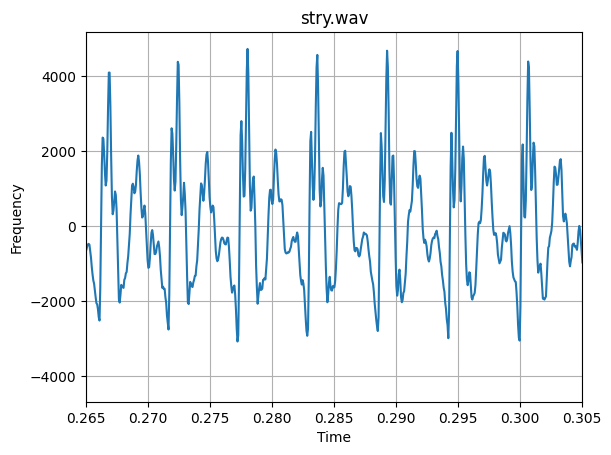

In [20]:

plt.plot(time, data)
plt.xlim(0.265, 0.305)
plt.ylabel("Frequency")
plt.xlabel("Time")
plt.title("stry.wav")
plt.grid()

plt.show()


### Task 3

Find the fundamental frequency $f_0$ of the vowel

In [21]:
print(f"We see that within the {40} ms window there is 7 pulses. \n The fundamental frequency f\u2080; if we divide the amount of pulses by the length of the signal\n is equal to: {7/0.04} Hz.")

We see that within the 40 ms window there is 7 pulses. 
 The fundamental frequency f₀; if we divide the amount of pulses by the length of the signal
 is equal to: 175.0 Hz.


## Problem 2: Spectral analysis


### Task 4

Estimate the spectrum of the vowel using an FFT of length 1024. Plot the spectrum expressed in dBs ($20 \log_{10}(x)$) as a function of frequency.

Useful Python functions: `numpy.fft.fft`, `numpy.abs`,

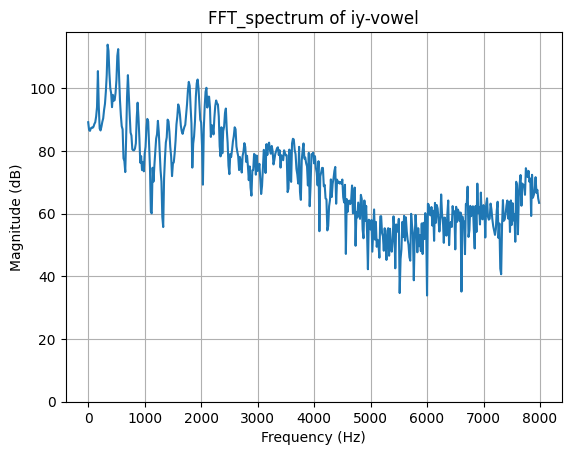

In [22]:
# ----- Given lines as in task 1 ------
# import relevant packages
import numpy as np
import scipy as sp
import scipy.io.wavfile

from matplotlib import pyplot as plt

# fetch and read the data
Fs, data = scipy.io.wavfile.read('stry.wav')
# ------------------------

#Spectrum length and start point
N = 1024
l_0 = int(0.265 * Fs)

#Segment of /iy/-vowel
segment = data[l_0 : l_0 + N]

X = np.fft.fft(segment, N)
freq = np.fft.fftfreq(N, 1/Fs)[:N//2]
magnitude_dB = 20 * np.log10(np.abs(X[:N//2]))

plt.plot(freq, magnitude_dB)
plt.ylim(bottom=0)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.title("FFT_spectrum of iy-vowel")
plt.grid()
plt.show()

### Task 5

Multiply the signal by a Hamming window and repeat the last operation. Explain the difference between the two spectra.

Useful Python functions: `scipy.signal.hamming`

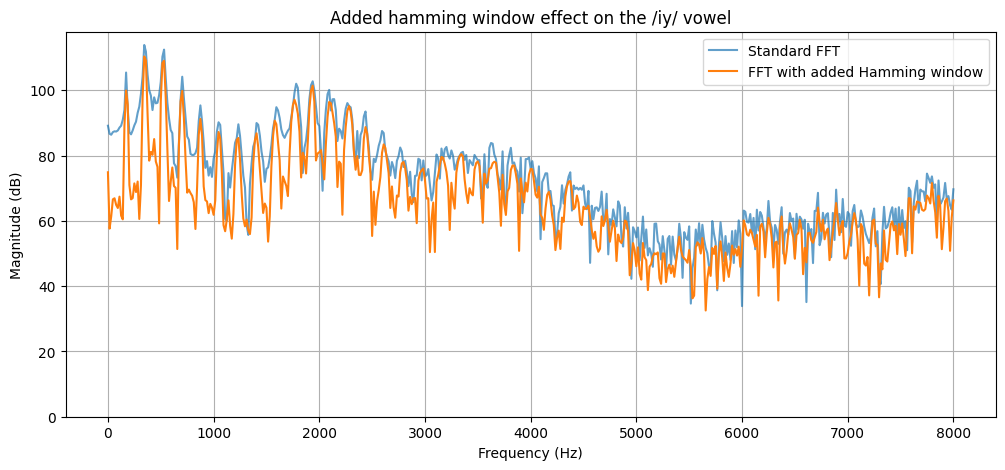

In [23]:
from scipy.signal.windows import hamming   # scipy.signal.hamming is deprecated; use this


N = 1024
l_0 = int(0.265 * Fs)
segment = data[l_0 : l_0 + N]

# --- Original (rectangular window) spectrum ---
X_rect = np.fft.fft(segment, N)

# --- Applying hamming window ---

X_win = np.fft.fft(segment * hamming(N), N)

freq = np.fft.rfftfreq(N, 1 / Fs)

X_rect = np.fft.rfft(segment, N)
X_win = np.fft.rfft(segment * hamming(N), N)

mag_rect_dB = 20 * np.log10(np.abs(X_rect))
mag_win_dB = 20 * np.log10(np.abs(X_win))
plt.figure(figsize=(12, 5))
plt.plot(freq, mag_rect_dB, label="Standard FFT", alpha = 0.7)
plt.plot(freq, mag_win_dB, label="FFT with added Hamming window")
plt.ylim(bottom=0)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.title("Added hamming window effect on the /iy/ vowel")
plt.legend()
plt.grid()
plt.show()



The function of a hamming window is to smooth out the edges of the speech signal. This so that the magnitude of the beginning and end stays the same.
In addition; the FFT with the applpied hamming window has a reduced magnitude in between the spectral peaks, and therefore less spectral liakage from peak to peak.

### Task 6

Estimate the fundamental frequency $f_0$ using the spectrum. Compare the result to what you got in Task 3.

343.75 Hz


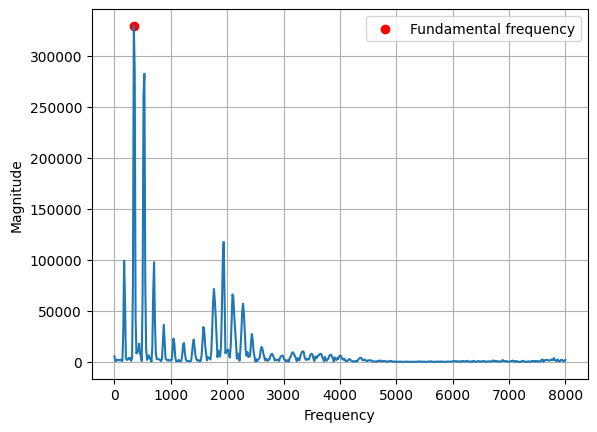

In [24]:
from scipy.signal import find_peaks

# Hamming-windowed spectrum
spectrum = np.abs(X_win)
spectrum_dB = 20 * np.log10(np.maximum(spectrum, np.finfo(float).eps))

peak_index = np.argmax(spectrum)

print(f"{freq[peak_index]} Hz")

plt.xlabel("Frequency")
plt.ylabel("Magnitude")
plt.grid()
plt.plot(freq, spectrum, label="")
plt.scatter(freq[peak_index],np.max(spectrum),color="r", label="Fundamental frequency")
plt.legend()
plt.show()



### Task 7

Roughly estimate the two first formant frequencies.

Estimated formants: [ 453.125 1937.5  ]


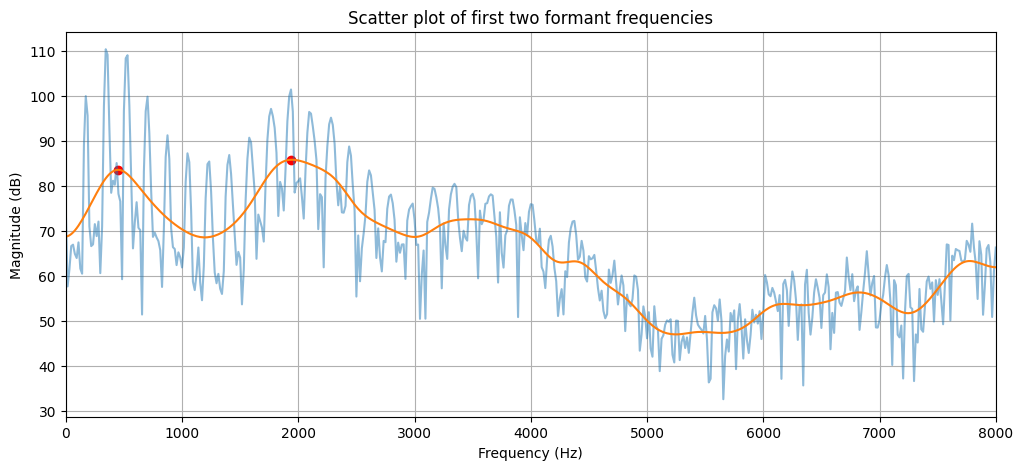

In [25]:
#filter to smooth out signal
from scipy.ndimage import gaussian_filter1d

spectrum_dB = 20 * np.log10(np.maximum(np.abs(X_win), 0))
smooth_spectrum = gaussian_filter1d(spectrum_dB, sigma=8) 
search_limit = (freq <= 3000)
peaks, _= find_peaks(smooth_spectrum[search_limit])
formant_freqs = freq[search_limit][peaks]


print("Estimated formants:", formant_freqs)

plt.figure(figsize=(12,5))
plt.plot(freq, spectrum_dB, alpha=0.5, label="Spectrum")
plt.plot(freq, smooth_spectrum, label="Smoothed spectrum")
plt.scatter(formant_freqs, smooth_spectrum[np.searchsorted(freq, formant_freqs)],color = "red",label="Estimated formant frequencies")


plt.xlim(0, 8000)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.title("Scatter plot of first two formant frequencies")
plt.grid()
plt.show()

## Problem 3: Autoregressive (AR) Modeling

### Task 8

Compute the coefficients of an AR model (linear prediction coefficients) with order 4, 8, 16 and 50, based on the vowel.

Useful Python functions: `pysptk.sptk.lpc`, `scipy.signal.freqz`. Check the documentation of the sptk package https://netix.dl.sourceforge.net/project/sp-tk to know which parameters are returned by the `lpc` function, and what model they correspond to.

`pysptk` is not pre-included with the standard Colab workspace, so we need to install in first. The next block has been set up to do so, but may take a minute or so to execute.

In [26]:
#! pip install pysptk

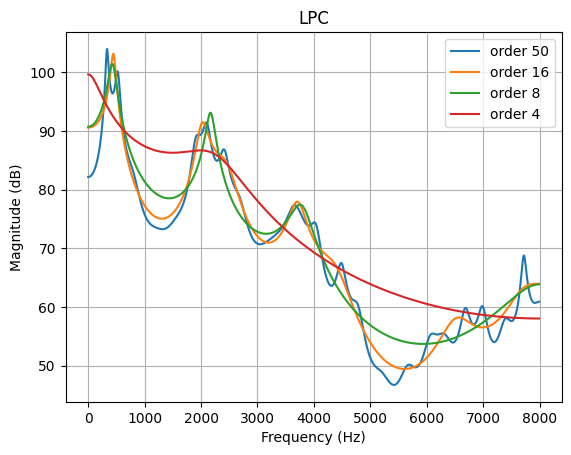

In [27]:

import pysptk

Fs, data = scipy.io.wavfile.read("stry.wav")
segment = data[int(0.30*Fs) : int(0.30*Fs) + int(0.04*Fs)].astype(np.float64)
segment *= np.hamming(len(segment))

orders = [4, 8, 16, 50]
orders.sort(reverse=True)

for i in orders:
    c = pysptk.sptk.lpc(segment, i)   # c[0] = gain K, c[1:] = a1..ap

    b = [c[0]]                            # numerator = gain
    a = np.concatenate(([1.0], c[1:]))    # denominator = 1 + a1*z^-1 + ...

    w, H = scipy.signal.freqz(b, a, worN=1024, fs=Fs)
    plt.plot(w, 20*np.log10(np.abs(H)), label=f"order {i}")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.title("LPC")
plt.legend()
plt.grid()
plt.show()

### Task 9

Estimate the spectrum for each of the model orders. Plot the spectrum in dBs as a function of frequency.

Compare your results with the spectrum from Tasks 5 and 6. Which model order yields the "best" spectral envelope? What happens if the model order is too high or too low?

Why is it not possible to estimate the fundamental frequency based on the LP model?

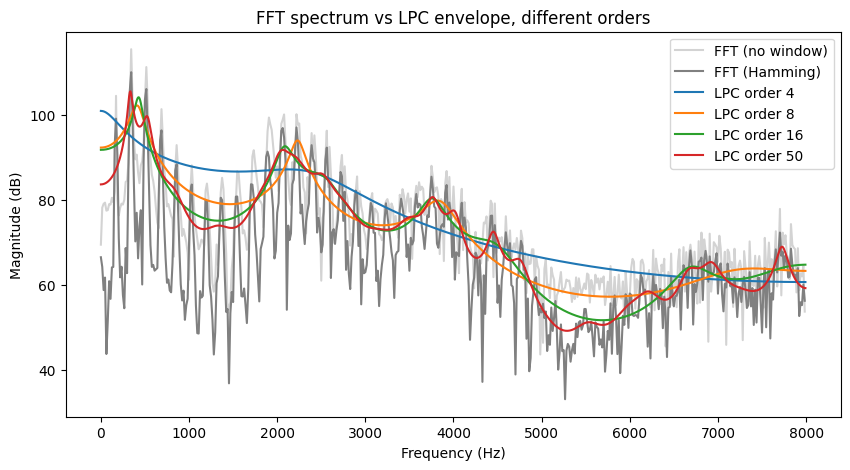

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import freqz
from scipy.signal.windows import hamming
import pysptk

Fs, data = wavfile.read("stry.wav")
N = 1024
i0 = int(0.30 * Fs)
segment = data[i0 : i0 + N].astype(np.float64)

# --- FFT spectrum (rectangular and Hamming, from Tasks 5 & 6) ---
X_rect = np.fft.fft(segment, N)
X_win  = np.fft.fft(segment * hamming(N), N)
freq_fft = np.fft.fftfreq(N, 1/Fs)[:N//2]
mag_rect_dB = 20*np.log10(np.abs(X_rect[:N//2]) + 1e-9)
mag_win_dB  = 20*np.log10(np.abs(X_win[:N//2])  + 1e-9)

# --- LPC spectrum for each order ---
seg_win = segment * hamming(N)
orders = [4, 8, 16, 50]

plt.figure(figsize=(10, 5))
plt.plot(freq_fft, mag_rect_dB, color='lightgray', label="FFT (no window)")
plt.plot(freq_fft, mag_win_dB,  color='gray',      label="FFT (Hamming)")

for order in orders:
    c = pysptk.sptk.lpc(seg_win, order)
    b = [c[0]]
    a = np.concatenate(([1.0], c[1:]))
    w, H = freqz(b, a, worN=1024, fs=Fs)
    plt.plot(w, 20*np.log10(np.abs(H)), label=f"LPC order {order}")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.title("FFT spectrum vs LPC envelope, different orders")
plt.legend()
plt.show()

## Problem 4: Spectrograms

### Task 10

Use `scipy.signal.spectrogram` to create a spectrogram of the entire speech signal. Try to generate both wide- and narrow-band spectrograms by adjusting the window lengths and overlaps. Which characteristic traits of the speech sounds /s/, /t/, /r/ and /iy/ can you see from the spectrogram?

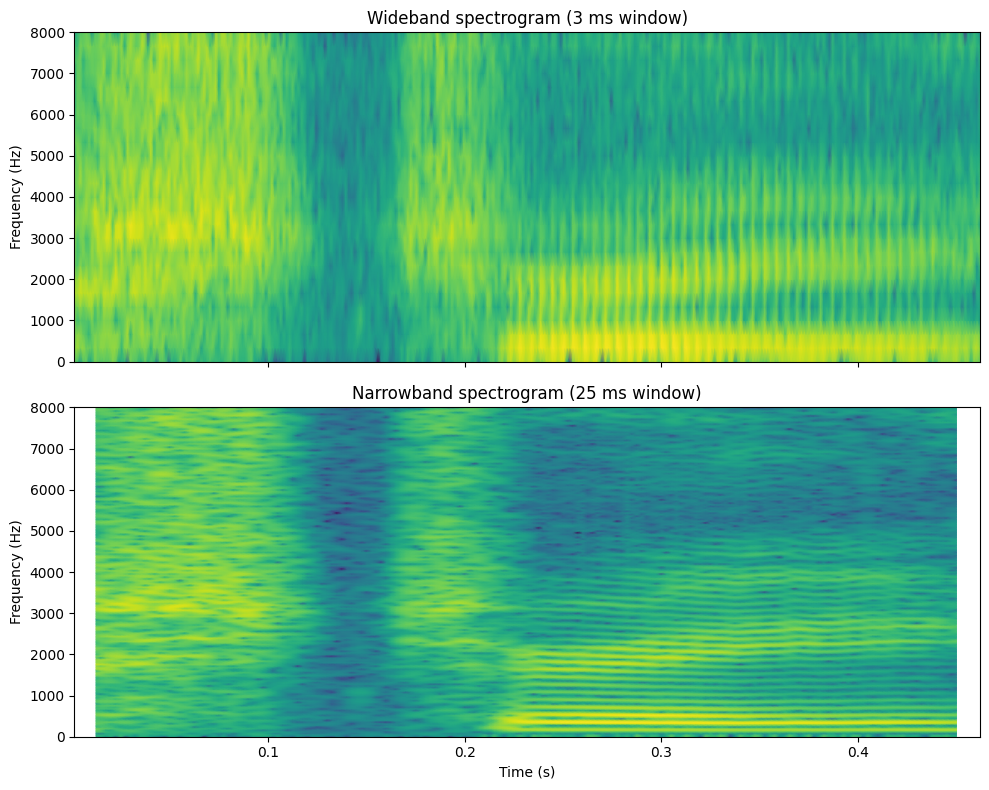

In [29]:
# --- Wideband: SHORT window -> good time resolution, poor frequency resolution ---
# Typically ~3 ms window. Shows individual glottal pulses as vertical striations.
nperseg_wide = int(0.003 * Fs)          # 3 ms
noverlap_wide = int(nperseg_wide * 0.5)

f_w, t_w, Sxx_w = scipy.signal.spectrogram(data, Fs, nperseg=nperseg_wide, noverlap=noverlap_wide, window='hamming')

# --- Narrowband: LONG window -> good frequency resolution, poor time resolution ---
# Typically ~25-30 ms window. Shows individual harmonics as horizontal lines.
nperseg_narrow = int(0.025 * Fs)        # 25 ms
noverlap_narrow = int(nperseg_narrow * 0.9)

f_n, t_n, Sxx_n = scipy.signal.spectrogram(data, Fs, nperseg=nperseg_narrow, noverlap=noverlap_narrow, window='hamming')

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

axes[0].pcolormesh(t_w, f_w, 10*np.log10(Sxx_w + 1e-12), shading='gouraud')
axes[0].set_title("Wideband spectrogram (3 ms window)")
axes[0].set_ylabel("Frequency (Hz)")

axes[1].pcolormesh(t_n, f_n, 10*np.log10(Sxx_n + 1e-12), shading='gouraud')
axes[1].set_title("Narrowband spectrogram (25 ms window)")
axes[1].set_ylabel("Frequency (Hz)")
axes[1].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

## Problem 5: Cepstrum

In this problem we look at the cepstrum and deconvolution

### Task 11

Compute and plot the real cepstrum of the vowel from Task 3

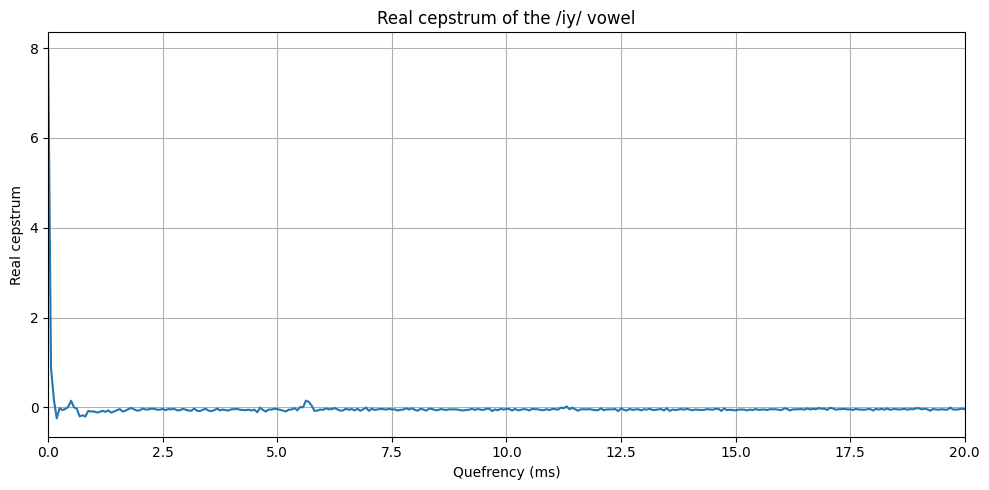

In [30]:
# Real cepstrum of the vowel from Task 3
l_0 = int(0.265 * Fs)
N = int(0.040 * Fs)
vowel = data[l_0:l_0 + N].astype(np.float64)
vowel -= np.mean(vowel)

N_fft = 1024
spectrum = np.fft.fft(vowel, n=N_fft)
log_magnitude_spectrum = np.log(np.maximum(np.abs(spectrum), np.finfo(float).eps))
real_cepstrum = np.real(np.fft.ifft(log_magnitude_spectrum))
quefrency = np.arange(N_fft) / Fs



plt.figure(figsize=(10, 5))
plt.plot(quefrency[:N_fft // 2] * 1000, real_cepstrum[:N_fft // 2])
plt.xlabel("Quefrency (ms)")
plt.ylabel("Real cepstrum")
plt.title("Real cepstrum of the /iy/ vowel")
plt.xlim(0, 20)
plt.grid(True)
plt.tight_layout()
plt.show()

### Task 12

Use the cepstrum to compute the fundamental frequency $f_0$. Compare your results with those obtained in Tasks 4 and 7.

In [31]:
min_f0 = 40    # Hz
max_f0 = 400  
min_quefrency = 1 / max_f0
max_quefrency = 1 / min_f0

search_indices = np.where((quefrency >= min_quefrency) & (quefrency <= max_quefrency))[0]
peak_index = search_indices[np.argmax(real_cepstrum[search_indices])]
fundamental_period = quefrency[peak_index]
f_0_cepstrum = 1 / fundamental_period

print(f"Estimated fundamental frequency: {f_0_cepstrum:.2f} Hz")


Estimated fundamental frequency: 177.78 Hz


We see that the estimated fundamental frequency $f_0$ corresponds pretty closely to the one calculated manually in task 3, but not with the one estimated in task 6. From this i believe that my strategy for task 6 must've been wrong.

### Task 13

Use the cepstrum to estimate the spectral envelope.

- Use liftering to extract the part of the ceptrum that represents the spectral envelope.
- Plot the spectral envelope as a function of frequency, and compare the result with the results from Task 10.

Hint 1: Remember that the cepstrum of a real signal is symmetric, so the liftered signal mus be symmetric as well.

Hint 2: The FFT of a real, symmtric signal is real, but due to round-off errors small imaginary noise may occur. Use `np.real` to get to the real part of the liftered log-spectrum.

In [1]:
import pandas as pd

# Create a sample DataFrame
data = {
    'Name': ['Alice', 'Bob', 'Charlie', 'David'],
    'City': ['New York', 'Los Angeles', 'Chicago', 'New York']
}
df = pd.DataFrame(data)

# Check which rows have 'New York' or 'Chicago'
target_cities = ['New York', 'Chicago']
mask = df['City'].isin(target_cities)

# Filter the DataFrame using the boolean mask
filtered_df = df[mask]
print(filtered_df)


      Name      City
0    Alice  New York
2  Charlie   Chicago
3    David  New York
